### Notebook Orchestration Functions Explained

This notebook demonstrates how to orchestrate and automate multiple notebook executions using Fabric's built-in orchestration APIs:

- `notebookutils.notebook.runMultiple([notebook_list])`  
  Runs multiple notebooks sequentially or in parallel. Pass a list of notebook names to execute simple workflows.

- `notebookutils.notebook.runMultiple(DAG, {"displayDAGViaGraphviz": True})`  
  Executes a Directed Acyclic Graph (DAG) of notebook activities. You can define dependencies, arguments, timeouts, and retry logic for each activity. Setting `displayDAGViaGraphviz` to `True` visually displays your workflow structure.

- Parameters and dependencies:  
  Each activity in the DAG can specify input parameters via `args`, a timeout, a retry policy, as well as dependencies on other activities for complex pipeline logic.

Refer to the code examples below for usage patterns.

## Simple runMUltiple call

In [1]:
notebookutils.notebook.runMultiple(["NotebookSimple", "NotebookSimple2"])

StatementMeta(, 48058634-0f46-4a8e-badd-893855025992, 3, Finished, Available, Finished, False)

{'0': {'exitVal': 'test', 'exception': None},
 '1': {'exitVal': 'test', 'exception': None}}

In [4]:
# run multiple notebooks with parameters
# Directed Acyclic Graph

DAG = {
    "activities": [
        {
            "name": "Process_1", # activity name, must be unique
            "path": "NotebookSimple", # notebook item name
            "timeoutPerCellInSeconds": 90, # max timeout for each cell, default to 90 seconds
            "args": {"p1": "changed value", "p2": 100}
            , # notebook parameters
            #"workspace":"WorkswpaceName" # both name and id are supported
        },
        {
            "name": "Process_2",
            "path": "NotebookSimple2",
            "timeoutPerCellInSeconds": 120,
            "args": {"p1": "changed value 2", "p2": 200}
            #,
            #"workspace":"id" # both name and id are supported
        },
        {
            "name": "Process_1.1",
            "path": "NotebookSimple2",
            "timeoutPerCellInSeconds": 120,
            "args": {"p1": "changed value 3", "p2": 300},
            "retry": 1,
            "retryIntervalInSeconds": 10,
            "dependencies": ["Process_1"] # list of activity names that this activity depends on
        }
    ],
    "timeoutInSeconds": 43200, # max timeout for the entire DAG, default to 12 hours
    "concurrency": 50 # max number of notebooks to run concurrently, default to 50
}

StatementMeta(, 48058634-0f46-4a8e-badd-893855025992, 6, Finished, Available, Finished, False)

StatementMeta(, 48058634-0f46-4a8e-badd-893855025992, 7, Finished, Available, Finished, False)

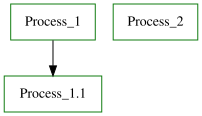

{'Process_1': {'exitVal': 'changed value', 'exception': None},
 'Process_2': {'exitVal': 'test', 'exception': None},
 'Process_1.1': {'exitVal': 'test', 'exception': None}}

In [5]:
notebookutils.notebook.runMultiple(DAG, {"displayDAGViaGraphviz": True})